# 02 - Exposure, Claim Count, and Severity EDA

In [15]:
# Import LIbraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import chi2

# Display all columns
pd.set_option('display.max_columns', None)

In [16]:
# Read merged data from Parquet file
fmv_df = pd.read_parquet("fmv_df.parquet")

fmv_df.head()

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,ClaimAmount
0,1.0,1,0.10,D,5,0,55,50,B12,'Regular',1217,R82,NaN
1,3.0,1,0.77,D,5,0,55,50,B12,'Regular',1217,R82,NaN
2,5.0,1,0.75,B,6,2,52,50,B12,'Diesel',54,R22,NaN
3,10.0,1,0.09,B,7,0,46,50,B12,'Diesel',76,R72,NaN
4,11.0,1,0.84,B,7,0,46,50,B12,'Diesel',76,R72,NaN


<Axes: >

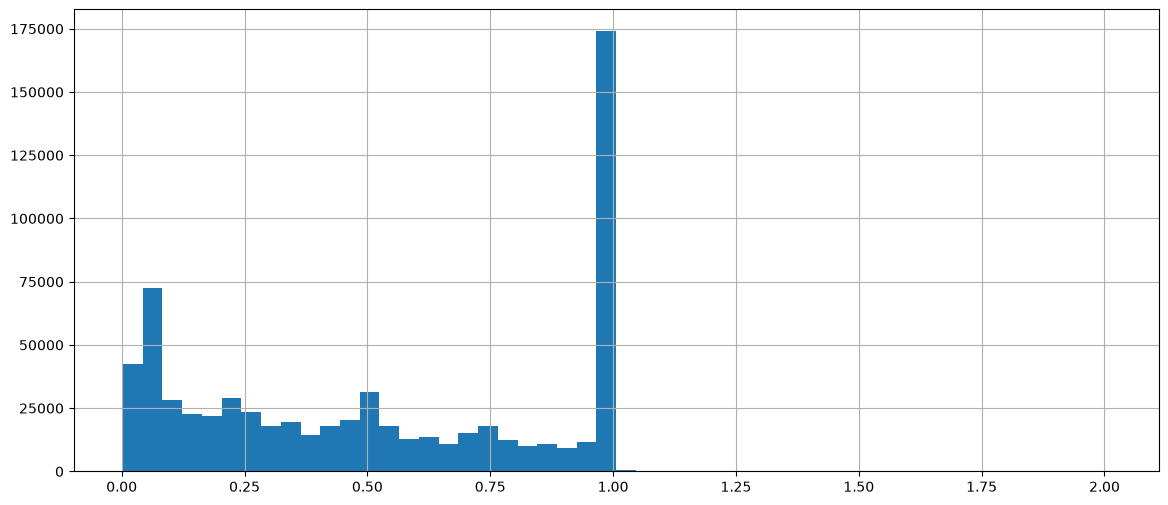

In [17]:
# Focus on Exposure
fmv_df["Exposure"].value_counts()

plt.figure(figsize=(14,6))

fmv_df["Exposure"].hist(bins=50)

############################## Takeaway ############################## 
# Exposures are mostly one year
# There is some concentration at under half a month


In [18]:
# Explore Claim Distribution
fmv_df['ClaimNb'].value_counts().sort_index()

ClaimNb
0     643953
1      32178
2       3082
3        206
4         22
5         10
6          6
8          8
9          9
11        23
16        16
Name: count, dtype: int64

In [19]:
# Proportion of exposure with at least 1 claim
avg_nonzero_claim = (fmv_df['ClaimNb'] > 0).mean()
print("Claim probability:", avg_nonzero_claim)

Claim probability: 0.05233159630500079


In [20]:
# Calculate overall claim frequency - Baseline Claim Frequency
total_claims = fmv_df['ClaimNb'].sum()
total_exposure = fmv_df['Exposure'].sum()

frequency = total_claims / total_exposure
print("Overall claim frequency:", frequency)

Overall claim frequency: 0.11067125054141724


In [21]:
# Explore claim severity
severity_df = fmv_df[fmv_df['ClaimAmount'] > 0]

severity_df['ClaimAmount'].describe()

# severity_df['ClaimAmount'].value_counts().sort_index()

count    2.644400e+04
mean     2.265513e+03
std      2.937103e+04
min      1.000000e+00
25%      6.859925e+02
50%      1.172000e+03
75%      1.212385e+03
max      4.075401e+06
Name: ClaimAmount, dtype: float64